# EDA, tiền xử lý và chuẩn hóa dữ liệu email

Notebook này khảo sát dữ liệu Enron-Spam, tái tạo các trường văn bản theo thư viện tiền xử lý dùng chung, tạo các tập train/validation/test cân bằng và tập email chưa gán nhãn cho demo. Các thống kê từ khóa chỉ được tính trên **train** để tránh rò rỉ dữ liệu.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    STOPWORDS,
    filter_stat_tokens,
    normalize_text,
    split_subject_body,
    tokenize,
)

DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option("display.max_colwidth", 100)
print(f"Thư mục dự án: {PROJECT_ROOT}")

Thư mục dự án: C:\Users\thang\OneDrive\Tài liệu\GitHub\spam-emails-team


## 1. Khám phá dữ liệu gốc

Đọc CSV được khởi tạo bởi `scripts/setup_data.py`. Kiểm tra cấu trúc, giá trị thiếu, bản ghi trùng và tính nhất quán giữa nhãn chữ với nhãn số trước khi phân tích.

In [2]:
raw_path = DATA_DIR / "processed" / "spam_ham_dataset.csv"
raw_df = pd.read_csv(raw_path)
print("Kích thước:", raw_df.shape)
print("Các cột:", raw_df.columns.tolist())
print("\nKiểu dữ liệu và số giá trị không rỗng:")
raw_df.info()
display(raw_df.head())

missing_counts = raw_df.isna().sum().rename("missing_count")
print("\nGiá trị thiếu theo cột:")
display(missing_counts.to_frame())
duplicate_count = int(raw_df.duplicated().sum())
print(f"Số hàng trùng hoàn toàn: {duplicate_count:,}")

label_text = raw_df["label"].astype("string").str.strip().str.lower()
label_num = pd.to_numeric(raw_df["label_num"], errors="coerce")
expected_num = label_text.map({"ham": 0, "spam": 1})
label_match = expected_num.notna() & label_num.eq(expected_num)
print(f"Số hàng có label/label_num khớp: {int(label_match.sum()):,}/{len(raw_df):,}")
print("Số hàng không khớp hoặc nhãn không hợp lệ:", int((~label_match).sum()))
print("\nPhân bố nhãn gốc:")
display(label_text.value_counts(dropna=False).rename_axis("label").to_frame("count"))

Kích thước: (5171, 4)
Các cột: ['Unnamed: 0', 'label', 'text', 'label_num']

Kiểu dữ liệu và số giá trị không rỗng:
<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 161.7 KB


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on mond...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 ...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - -...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fort...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understandi...,0



Giá trị thiếu theo cột:


,missing_count
Unnamed: 0,0
label,0
text,0
label_num,0


Số hàng trùng hoàn toàn: 0
Số hàng có label/label_num khớp: 5,171/5,171
Số hàng không khớp hoặc nhãn không hợp lệ: 0

Phân bố nhãn gốc:


,count
label,
ham,3672
spam,1499


### Phân bố nhãn

Biểu đồ thể hiện số lượng và tỷ lệ của hai lớp trong dữ liệu gốc. Dữ liệu có thể mất cân bằng; các tập chuẩn được lấy mẫu cân bằng ở bước tiếp theo để thuận tiện so sánh mô hình.

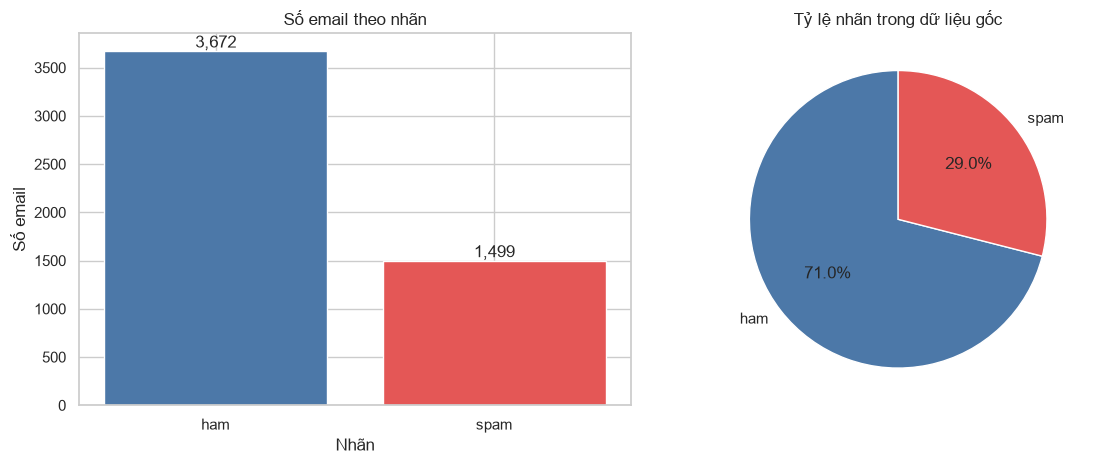

Đã lưu: outputs\figures\eda_label_distribution.png


In [3]:
label_counts = label_text.value_counts().reindex(["ham", "spam"], fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
palette = {"ham": "#4C78A8", "spam": "#E45756"}
axes[0].bar(label_counts.index, label_counts.values,
            color=[palette[label] for label in label_counts.index])
axes[0].set_title("Số email theo nhãn")
axes[0].set_xlabel("Nhãn")
axes[0].set_ylabel("Số email")
for index, value in enumerate(label_counts.values):
    axes[0].text(index, value, f"{value:,}", ha="center", va="bottom")

axes[1].pie(label_counts.values, labels=label_counts.index, autopct="%1.1f%%",
            colors=[palette[label] for label in label_counts.index], startangle=90)
axes[1].set_title("Tỷ lệ nhãn trong dữ liệu gốc")
fig.tight_layout()
label_figure = FIGURES_DIR / "eda_label_distribution.png"
fig.savefig(label_figure, dpi=160, bbox_inches="tight")
plt.show()
print("Đã lưu:", label_figure.relative_to(PROJECT_ROOT))

### Độ dài email theo lớp

Dùng hàm lõi để tách tiêu đề và nội dung. Độ dài từ được tính trên văn bản đã chuẩn hóa; bảng thống kê gồm trung bình và trung vị, còn biểu đồ hộp giúp quan sát độ phân tán và các giá trị ngoại lệ.

,email_count,mean_words,median_words
label,,,
ham,3672,155.02,84.0
spam,1499,185.15,86.0


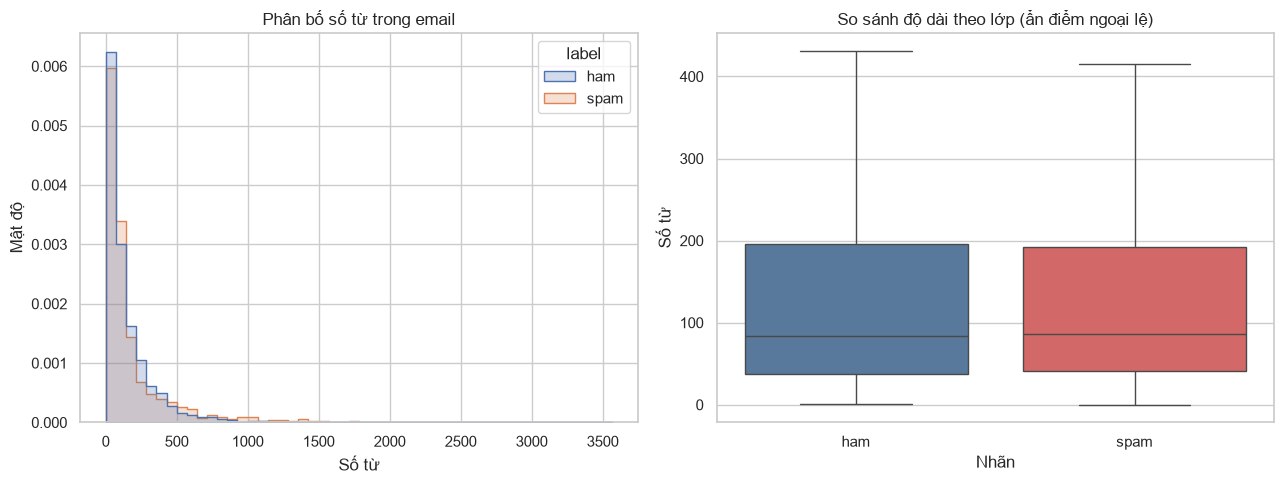

Đã lưu: outputs\figures\eda_length_distribution.png


In [4]:
length_df = raw_df[["text", "label"]].copy()
length_parts = length_df["text"].fillna("").map(split_subject_body)
length_df["subject"] = length_parts.map(lambda parts: parts[0])
length_df["body"] = length_parts.map(lambda parts: parts[1])
length_df["word_count"] = [
    len(tokenize(f"{subject} {body}"))
    for subject, body in zip(length_df["subject"], length_df["body"])
]
length_summary = length_df.groupby("label")["word_count"].agg(
    email_count="size", mean_words="mean", median_words="median"
).reindex(["ham", "spam"])
display(length_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=length_df, x="word_count", hue="label", bins=50,
             element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Phân bố số từ trong email")
axes[0].set_xlabel("Số từ")
axes[0].set_ylabel("Mật độ")
sns.boxplot(data=length_df, x="label", y="word_count", hue="label",
            order=["ham", "spam"], hue_order=["ham", "spam"],
            palette=palette, showfliers=False, legend=False, ax=axes[1])
axes[1].set_title("So sánh độ dài theo lớp (ẩn điểm ngoại lệ)")
axes[1].set_xlabel("Nhãn")
axes[1].set_ylabel("Số từ")
fig.tight_layout()
length_figure = FIGURES_DIR / "eda_length_distribution.png"
fig.savefig(length_figure, dpi=160, bbox_inches="tight")
plt.show()
print("Đã lưu:", length_figure.relative_to(PROJECT_ROOT))

## 2. Tiền xử lý, chuẩn hóa nhãn và chia tập

Tách `subject`/`body` bằng `split_subject_body`, chuẩn hóa `label` và `label_num`, tạo `clean_text` bằng `normalize_text` (giữ stopwords) và `stat_text` bằng `tokenize` + `filter_stat_tokens`. Loại email rỗng, sai/không khớp nhãn và khử trùng theo `clean_text` **trước khi lấy mẫu, chia tập**. Chỉ chọn 250 email mỗi lớp; chia theo số lượng cố định với seed 42.

In [5]:
processed = raw_df[["label", "label_num", "text"]].copy()
processed["label"] = processed["label"].astype("string").str.strip().str.lower()
processed["label_num"] = pd.to_numeric(processed["label_num"], errors="coerce")
parts = processed["text"].fillna("").map(split_subject_body)
processed["subject"] = parts.map(lambda value: " ".join(value[0].split()))
processed["body"] = parts.map(lambda value: " ".join(value[1].split()))

valid_label = processed["label"].isin(["spam", "ham"])
expected_label_num = processed["label"].map({"ham": 0, "spam": 1})
valid_pair = processed["label_num"].eq(expected_label_num)
nonempty_email = processed["subject"].ne("") | processed["body"].ne("")
valid_rows = valid_label & valid_pair & nonempty_email
invalid_rows_removed = int((~valid_rows).sum())
processed = processed.loc[valid_rows].copy()
processed["label_num"] = expected_label_num.loc[valid_rows].astype("int64")
processed["clean_text"] = [
    normalize_text(f"{subject} {body}")
    for subject, body in zip(processed["subject"], processed["body"])
]
processed["stat_text"] = [
    " ".join(filter_stat_tokens(tokenize(clean_text)))
    for clean_text in processed["clean_text"]
]
empty_clean_rows = int(processed["clean_text"].eq("").sum())
processed = processed.loc[processed["clean_text"].ne("")].copy()

before_dedup = len(processed)
processed = processed.drop_duplicates(subset="clean_text", keep="first").copy()
duplicates_removed = before_dedup - len(processed)
print(f"Hàng loại do nhãn không hợp lệ/không khớp hoặc email rỗng: {invalid_rows_removed:,}")
print(f"Hàng loại do clean_text rỗng: {empty_clean_rows:,}")
print(f"Email trùng clean_text đã loại trước khi chia: {duplicates_removed:,}")
print("Số email hợp lệ, duy nhất:", f"{len(processed):,}")
display(processed[["subject", "body", "clean_text", "stat_text", "label", "label_num"]].head(3))

Hàng loại do nhãn không hợp lệ/không khớp hoặc email rỗng: 16
Hàng loại do clean_text rỗng: 1
Email trùng clean_text đã loại trước khi chia: 267
Số email hợp lệ, duy nhất: 4,887


,subject,body,clean_text,stat_text,label,label_num
0,enron methanol ; meter # : 988291,"this is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary flow data provid...",enron methanol meter 988291 this is a follow up to the note i gave you on monday 4 3 00 prelimin...,enron methanol meter 988291 follow note gave monday 00 preliminary flow data provided daren plea...,ham,0
1,"hpl nom for january 9 , 2001",( see attached file : hplnol 09 . xls ) - hplnol 09 . xls,hpl nom for january 9 2001 see attached file hplnol 09 xls hplnol 09 xls,hpl nom january 2001 see attached file hplnol 09 xls hplnol 09 xls,ham,0
2,neon retreat,"ho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat tim...",neon retreat ho ho ho we re around to that most wonderful time of the year neon leaders retreat ...,neon retreat ho ho ho re around most wonderful time year neon leaders retreat time know time yea...,ham,0


In [6]:
SEED = 42
OUTPUT_COLUMNS = [
    "email_id", "subject", "body", "clean_text", "stat_text", "label", "label_num"
]
SPLIT_SIZES = {
    "spam": {"train": 175, "validation": 38, "test": 37},
    "ham": {"train": 175, "validation": 37, "test": 38},
}

selected_by_class = []
for label in ("spam", "ham"):
    class_rows = processed.loc[processed["label"].eq(label)]
    assert len(class_rows) >= 250, f"Không đủ 250 email lớp {label}."
    selected_by_class.append(class_rows.sample(n=250, random_state=SEED))

selected = pd.concat(selected_by_class, ignore_index=True)
selected = selected.sample(frac=1, random_state=SEED).reset_index(drop=True)
selected.insert(0, "email_id", [f"E{number:04d}" for number in range(1, 501)])

split_parts = {"train": [], "validation": [], "test": []}
for label in ("spam", "ham"):
    class_rows = selected.loc[selected["label"].eq(label)].sample(
        frac=1, random_state=SEED
    )
    sizes = SPLIT_SIZES[label]
    train_end = sizes["train"]
    validation_end = train_end + sizes["validation"]
    split_parts["train"].append(class_rows.iloc[:train_end])
    split_parts["validation"].append(class_rows.iloc[train_end:validation_end])
    split_parts["test"].append(class_rows.iloc[validation_end:])

train_df, validation_df, test_df = {
    name: pd.concat(parts_for_split, ignore_index=True)[OUTPUT_COLUMNS]
    for name, parts_for_split in split_parts.items()
}.values()

def verify_split_integrity(train, validation, test):
    expected_sizes = {"train": 350, "validation": 75, "test": 75}
    frames = {"train": train, "validation": validation, "test": test}
    for name, frame in frames.items():
        assert frame.columns.tolist() == OUTPUT_COLUMNS
        assert len(frame) == expected_sizes[name]
        assert frame["clean_text"].is_unique
    assert len(set(train["clean_text"]) & set(validation["clean_text"])) == 0
    assert len(set(train["clean_text"]) & set(test["clean_text"])) == 0
    assert len(set(validation["clean_text"]) & set(test["clean_text"])) == 0
    assert train["label"].value_counts().to_dict() == {"spam": 175, "ham": 175}
    assert validation["label"].value_counts().to_dict() == {"spam": 38, "ham": 37}
    assert test["label"].value_counts().to_dict() == {"ham": 38, "spam": 37}

verify_split_integrity(train_df, validation_df, test_df)
train_df.to_csv(DATA_DIR / "train.csv", index=False, encoding="utf-8")
validation_df.to_csv(DATA_DIR / "validation.csv", index=False, encoding="utf-8")
test_df.to_csv(DATA_DIR / "test.csv", index=False, encoding="utf-8")

remaining = processed.loc[~processed["clean_text"].isin(selected["clean_text"])]
unlabeled = remaining.sample(n=30, random_state=SEED).reset_index(drop=True)
unlabeled.insert(0, "email_id", [f"U{number:03d}" for number in range(1, 31)])
unlabeled = unlabeled[["email_id", "subject", "body", "clean_text", "stat_text"]]
assert len(unlabeled) == 30
assert unlabeled["email_id"].tolist() == [f"U{number:03d}" for number in range(1, 31)]
assert set(unlabeled["clean_text"]).isdisjoint(set(selected["clean_text"]))
unlabeled.to_csv(DATA_DIR / "unlabeled_sample.csv", index=False, encoding="utf-8")

for name, frame in (("train", train_df), ("validation", validation_df), ("test", test_df)):
    print(f"{name}: {len(frame)} dòng; phân bố nhãn = {frame['label'].value_counts().to_dict()}")
print(f"unlabeled_sample: {len(unlabeled)} dòng; cột nhãn đã được loại bỏ")
print("Các tập đã được lưu trong:", DATA_DIR)

train: 350 dòng; phân bố nhãn = {'spam': 175, 'ham': 175}
validation: 75 dòng; phân bố nhãn = {'spam': 38, 'ham': 37}
test: 75 dòng; phân bố nhãn = {'ham': 38, 'spam': 37}
unlabeled_sample: 30 dòng; cột nhãn đã được loại bỏ
Các tập đã được lưu trong: C:\Users\thang\OneDrive\Tài liệu\GitHub\spam-emails-team\data


### Kiểm tra cấu trúc và chống rò rỉ

Ba tập có đúng bảy cột chuẩn, đúng kích thước và phân bố lớp đã thống nhất. Các assertion kiểm tra giao `clean_text` giữa mọi cặp tập bằng rỗng. Tập demo không chứa email nào trong 500 email đã chọn và không xuất nhãn thật.

In [7]:
verify_split_integrity(train_df, validation_df, test_df)
assert set(unlabeled.columns) == {"email_id", "subject", "body", "clean_text", "stat_text"}
assert set(train_df["clean_text"]).isdisjoint(validation_df["clean_text"])
assert set(train_df["clean_text"]).isdisjoint(test_df["clean_text"])
assert set(validation_df["clean_text"]).isdisjoint(test_df["clean_text"])
print("PASS: schema, kích thước, phân bố nhãn và tính độc lập giữa các tập.")
print("STOPWORDS dùng cho stat_text:", len(STOPWORDS), "từ")
print("Ví dụ stat_text:", train_df.loc[train_df.index[0], "stat_text"][:180])

PASS: schema, kích thước, phân bố nhãn và tính độc lập giữa các tập.
STOPWORDS dùng cho stat_text: 80 từ
Ví dụ stat_text: pleasure all um ambl en xanaax tussioneex clal 11 agrra adlpex 65 position run list bit xanaax alium cialiis iaagra ambieen all popular medssno long questioning form pay shiip toda


### 20 từ phổ biến nhất theo lớp (chỉ trên train)

Đếm token sau khi áp dụng đúng `filter_stat_tokens` từ `src.preprocessing`. Biểu đồ chỉ dùng 350 email train; validation và test không tham gia lựa chọn hay khảo sát từ khóa.

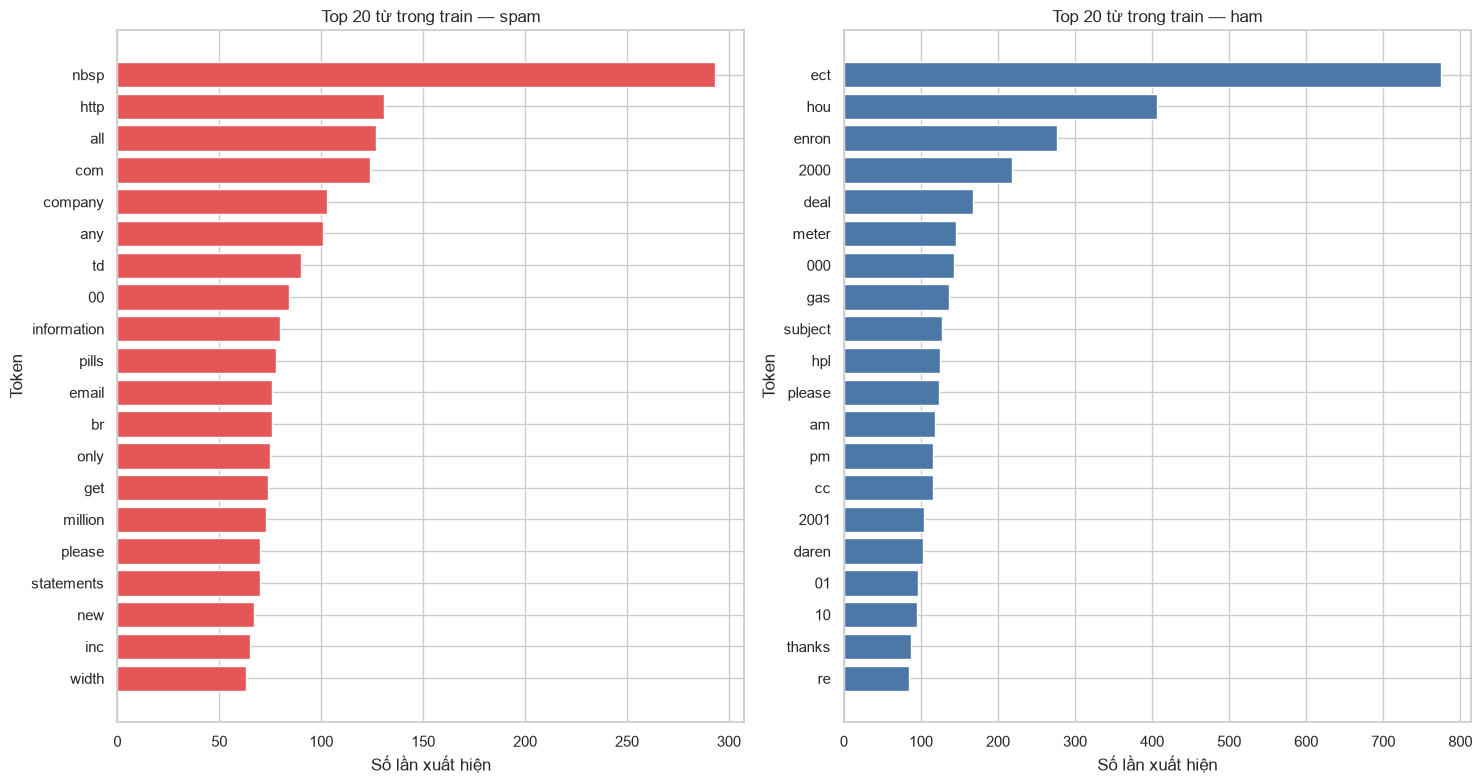

Top 5 spam: [('nbsp', 293), ('http', 131), ('all', 127), ('com', 124), ('company', 103)]
Top 5 ham: [('ect', 775), ('hou', 406), ('enron', 277), ('2000', 218), ('deal', 168)]
Đã lưu: outputs\figures\eda_top_words.png


In [8]:
word_counts = {}
for label in ("spam", "ham"):
    tokens = []
    for text in train_df.loc[train_df["label"].eq(label), "clean_text"]:
        tokens.extend(filter_stat_tokens(tokenize(text)))
    word_counts[label] = Counter(tokens)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for axis, label in zip(axes, ("spam", "ham")):
    top_words = word_counts[label].most_common(20)
    words, counts = zip(*top_words) if top_words else ([], [])
    axis.barh(list(reversed(words)), list(reversed(counts)), color=palette[label])
    axis.set_title(f"Top 20 từ trong train — {label}")
    axis.set_xlabel("Số lần xuất hiện")
    axis.set_ylabel("Token")
fig.tight_layout()
top_words_figure = FIGURES_DIR / "eda_top_words.png"
fig.savefig(top_words_figure, dpi=160, bbox_inches="tight")
plt.show()
print("Top 5 spam:", word_counts["spam"].most_common(5))
print("Top 5 ham:", word_counts["ham"].most_common(5))
print("Đã lưu:", top_words_figure.relative_to(PROJECT_ROOT))

## 3. Nhận xét EDA và kết quả

- Dữ liệu gốc có phân bố nhãn không cân bằng; vì vậy bộ dữ liệu chuẩn được lấy cân bằng 250 spam và 250 ham trước khi chia.
- Biểu đồ độ dài và bảng trung bình/trung vị cho thấy mức độ biến thiên của email trong từng lớp; email rất dài tạo phần đuôi phân phối và được biểu diễn riêng qua boxplot.
- Top từ trong train minh họa khác biệt từ vựng giữa Spam và Ham. Các token phổ biến là dấu hiệu mô tả dữ liệu, không phải xác suất phân loại.
- Dữ liệu được khử trùng theo `clean_text` trước khi chia; các assertion xác nhận không có email trùng giữa train, validation và test.
- `clean_text` giữ stopwords cho Rule; `stat_text` bỏ đúng stopwords dùng chung và token dưới 2 ký tự. Tập demo chỉ giữ các trường văn bản, không chứa nhãn.

In [9]:
print("Tóm tắt số liệu để cập nhật docs/data_description.md")
print(f"Dữ liệu gốc: {len(raw_df):,} email; ham={int(label_counts['ham']):,}; spam={int(label_counts['spam']):,}")
print(f"Thiếu dữ liệu: {int(raw_df.isna().sum().sum()):,}; trùng hoàn toàn: {duplicate_count:,}")
print(f"Hàng loại khi chuẩn hóa: {invalid_rows_removed + empty_clean_rows:,}; trùng clean_text loại trước chia: {duplicates_removed:,}")
print("Độ dài từ theo lớp (trung bình / trung vị):")
display(length_summary.round(2))
print("Tập train / validation / test:", len(train_df), "/", len(validation_df), "/", len(test_df))
print("Unlabeled:", len(unlabeled))
print("Biểu đồ:", *(path.name for path in (label_figure, length_figure, top_words_figure)))

Tóm tắt số liệu để cập nhật docs/data_description.md
Dữ liệu gốc: 5,171 email; ham=3,672; spam=1,499
Thiếu dữ liệu: 0; trùng hoàn toàn: 0
Hàng loại khi chuẩn hóa: 17; trùng clean_text loại trước chia: 267
Độ dài từ theo lớp (trung bình / trung vị):


,email_count,mean_words,median_words
label,,,
ham,3672,155.02,84.0
spam,1499,185.15,86.0


Tập train / validation / test: 350 / 75 / 75
Unlabeled: 30
Biểu đồ: eda_label_distribution.png eda_length_distribution.png eda_top_words.png
